In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
from matplotlib.patches import Circle
import matplotlib as mpl
import seaborn as sns
import h5py
import time
import scipy.sparse as sp
import yaml
import gc
from matplotlib import gridspec

from datetime import datetime

import anndata as an
import scanpy as sc

sc.settings.verbosity = 3

In [2]:
%%time
# Built from Hematokytos/pipelines/reference_atlas/DEG/
fpath = "/nfs/turbo/umms-indikar/shared/projects/HSC/pipeline_outputs/hematokytos/sample_1_adata_cell_type_deg.parquet"

df = pd.read_parquet(fpath)
print(f"Raw data shape: {df.shape=}")
df = df.sort_values(by=['group', 'logfoldchanges'], ascending=[True, False])

df.head()

Raw data shape: df.shape=(6103188, 8)
CPU times: user 5.35 s, sys: 1.8 s, total: 7.16 s
Wall time: 7.29 s


,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
5516,B-2 B cell,IGKV2OR2-10,0.058087,9.903637,0.953679,0.999987,0.001127,8.977733e-07
5520,B-2 B cell,IGHV3-47,0.057810,8.766234,0.953900,0.999987,0.001127,6.284413e-06
5034,B-2 B cell,IGKV2-40,0.173477,8.730827,0.862276,0.999987,0.003382,1.795547e-05
3613,B-2 B cell,IGLV1-50,0.983110,7.728125,0.325553,0.999987,0.019166,1.005506e-04
5045,B-2 B cell,IGKV1D-37,0.172185,7.695893,0.863292,0.999987,0.003382,4.309312e-05


In [4]:
df['group'].value_counts()

group
B-2 B cell                                               52164
CD16-negative, CD56-bright natural killer cell, human    52164
CD16-positive, CD56-dim natural killer cell, human       52164
CD1c-positive myeloid dendritic cell                     52164
CD4-positive helper T cell                               52164
                                                         ...  
thymocyte                                                52164
tonsil germinal center B cell                            52164
transitional stage B cell                                52164
vascular associated smooth muscle cell                   52164
vein endothelial cell                                    52164
Name: count, Length: 117, dtype: int64

In [3]:
cell_type_compartments = {
    # "lymphoid": [
    #     'B-2 B cell', 'class switched memory B cell', 'follicular B cell',
    #     'memory B cell', 'naive B cell', 'plasma cell', 'plasmablast',
    #     'precursor B cell', 'pro-B cell', 'transitional stage B cell',
    #     'tonsil germinal center B cell',
    #     'CD4-positive helper T cell', 'CD4-positive, alpha-beta cytotoxic T cell',
    #     'CD4-positive, alpha-beta memory T cell', 'CD4-positive, alpha-beta thymocyte',
    #     'CD8-alpha-alpha-positive, alpha-beta intraepithelial T cell',
    #     'CD8-positive, alpha-beta cytotoxic T cell',
    #     'CD8-positive, alpha-beta memory T cell',
    #     'central memory CD4-positive, alpha-beta T cell',
    #     'central memory CD8-positive, alpha-beta T cell',
    #     'effector CD4-positive, alpha-beta T cell',
    #     'effector CD8-positive, alpha-beta T cell',
    #     'effector memory CD4-positive, alpha-beta T cell',
    #     'effector memory CD8-positive, alpha-beta T cell',
    #     'activated CD4-positive, alpha-beta T cell',
    #     'activated CD8-positive, alpha-beta T cell',
    #     'naive thymus-derived CD4-positive, alpha-beta T cell',
    #     'naive thymus-derived CD8-positive, alpha-beta T cell',
    #     'alpha-beta T cell', 'gamma-delta T cell', 'mucosal invariant T cell',
    #     'double-positive, alpha-beta thymocyte', 'double negative thymocyte',
    #     'thymocyte', 'T follicular helper cell',
    #     'NKp44-negative group 3 innate lymphoid cell, human',
    #     'NKp44-positive group 3 innate lymphoid cell, human',
    #     'group 2 innate lymphoid cell', 'group 3 innate lymphoid cell',
    #     'group 3 innate lymphoid cell, human',
    #     'immature innate lymphoid cell', 'decidual natural killer cell, human',
    #     'CD16-negative, CD56-bright natural killer cell, human',
    #     'CD16-positive, CD56-dim natural killer cell, human',
    #     'lymphocyte'
    # ],
    # "myeloid": [
    #     'classical monocyte', 'non-classical monocyte', 'myelocyte',
    #     'neutrophil', 'inflammatory macrophage', 'alveolar macrophage',
    #     'central nervous system macrophage',
    #     'conventional dendritic cell', 'plasmacytoid dendritic cell',
    #     'CD1c-positive myeloid dendritic cell', 'common dendritic progenitor',
    #     'mast cell', 'myeloid cell'
    # ],
    "progenitor": [
        'hematopoietic stem cell', 'cord blood hematopoietic stem cell',
        'hematopoietic multipotent progenitor cell',
        'hematopoietic precursor cell', 'common myeloid progenitor',
        'erythroid progenitor cell', 'megakaryocyte-erythroid progenitor cell',
        'megakaryocyte progenitor cell', 'lymphoid lineage restricted progenitor cell',
        'early lymphoid progenitor', 'fibro/adipogenic progenitor cell',
        'common dendritic progenitor', 'hematopoietic cell',
    ],
    # "erythroid/megakaryocyte": [
    #     'erythroblast', 'erythrocyte', 'primitive red blood cell',
    #     'megakaryocyte', 'platelet'
    # ],
    "endothelial": [
        'endothelial cell', 'capillary endothelial cell', 'gut endothelial cell',
        'blood vessel endothelial cell', 'brain vascular cell', 'cerebral cortex endothelial cell',
        'cardiac endothelial cell', 'pulmonary artery endothelial cell',
        'vein endothelial cell', 'endothelial cell of artery',
        'endothelial cell of lymphatic vessel',
        'endothelial cell of pericentral hepatic sinusoid',
        'endothelial cell of placenta', 'endothelial cell of uterus',
        'endothelial cell of vascular tree', 'endothelial cell of venule',
        'endothelial tip cell'
    ],
    "fibroblast/mesenchymal": [
        'fibroblast', 'fibroblast of lung', 'fibroblast of cardiac tissue',
        'fibroblast of mammary gland', 'skin fibroblast',
        'bronchus fibroblast of lung', 'pulmonary interstitial fibroblast',
        'skeletal muscle fibroblast', 'embryonic fibroblast',
        'alveolar type 1 fibroblast cell', 'alveolar type 2 fibroblast cell',
        'myofibroblast cell', 'mesenchymal cell', 'mesenchymal stem cell'
    ],
    # "stromal/vascular support": [
    #     'mural cell', 'pericyte', 'lung pericyte', 'kidney interstitial fibroblast',
    #     'hepatic stellate cell', 'vascular associated smooth muscle cell',
    #     'smooth muscle cell of the pulmonary artery', 'mesothelial cell',
    #     'adipocyte'
    # ],
}

In [4]:
# load tf list
fpath = "../resources/allTFs_hg38.txt"
tf_list = [x.strip() for x in open(fpath)]
print(f"{len(tf_list)=}")
tf_list[:10]

len(tf_list)=1892


['ZNF354C',
 'KLF12',
 'ZNF143',
 'ZIC2',
 'ZNF274',
 'SP2',
 'ZBTB7A',
 'BCL6B',
 'ZBTB49',
 'ZIC1']

In [22]:
from collections import defaultdict

def get_unique_degs(filtered_df, top_n, groups):
    sub = filtered_df[filtered_df['group'].isin(groups)].copy()
    sub = sub.sort_values(['group', 'logfoldchanges'], ascending=[True, False])

    sorted_groups = sub['group'].unique()
    
    unique_genes = []
    assigned_genes = set()
    for group in sorted_groups:
        group_df = sub[sub['group'] == group].copy()
        count = 0
        for _, row in group_df.iterrows():
            gene = row['names']
            if gene not in assigned_genes:
                unique_genes.append(gene)
                assigned_genes.add(gene)
                count += 1
            if count == top_n:
                break
    return unique_genes

In [23]:
filtered_df = df[
    (df['pct_nz_group'] > pct_nz_group) &
    (df['pvals_adj'] < pvals_adj) &
    (df['logfoldchanges'] > logfoldchanges)
]

# Drop gene classes
filtered_df = filtered_df[
    ~filtered_df['names'].str.contains("ENSG") &
    ~filtered_df['names'].str.startswith(("LINC", "MT", "RP"))
].copy()

cell_list = ['hematopoietic stem cell', 'cord blood hematopoietic stem cell',
        'hematopoietic multipotent progenitor cell',
        'hematopoietic precursor cell', 'common myeloid progenitor',
        'erythroid progenitor cell', 'megakaryocyte-erythroid progenitor cell',
        'megakaryocyte progenitor cell', 'lymphoid lineage restricted progenitor cell',
        'early lymphoid progenitor', 'fibro/adipogenic progenitor cell',
        'common dendritic progenitor', 'hematopoietic cell']

deg_genes = get_unique_degs(filtered_df, 3, cell_list)
print(len(deg_genes))
deg_genes

39


['SHD',
 'IRF8',
 'IGLL1',
 'MPO',
 'AZU1',
 'PRTN3',
 'SPINK2',
 'FAM30A',
 'SNHG29',
 'VPREB1',
 'UMODL1',
 'ACY3',
 'CA1',
 'HBD',
 'FAM178B',
 'SLC7A14-AS1',
 'FGGY-DT',
 'NEGR1',
 'FOLR2',
 'AGR2',
 'HBA2',
 'AVP',
 'NPR3',
 'SMIM24',
 'HTR1F',
 'XACT',
 'PRKG2',
 'PRSS57',
 'PRSS2',
 'TRH',
 'H3C2',
 'DNTT',
 'PROM1',
 'ITGA2B',
 'FCER1A',
 'MPL',
 'SVOPL',
 'HYAL3',
 'DHRS9']

In [16]:
cell_list_sorted = sorted(cell_list)
cell_list_sorted

['common dendritic progenitor',
 'common myeloid progenitor',
 'cord blood hematopoietic stem cell',
 'early lymphoid progenitor',
 'erythroid progenitor cell',
 'fibro/adipogenic progenitor cell',
 'hematopoietic cell',
 'hematopoietic multipotent progenitor cell',
 'hematopoietic precursor cell',
 'hematopoietic stem cell',
 'lymphoid lineage restricted progenitor cell',
 'megakaryocyte progenitor cell',
 'megakaryocyte-erythroid progenitor cell']

In [25]:
filtered_df[filtered_df['group'] == 'common myeloid progenitor'].head()

,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
1773577,common myeloid progenitor,MPO,73.724976,8.414395,0.0,0.0,0.850096,0.023507
1773585,common myeloid progenitor,AZU1,66.769707,8.405719,0.0,0.0,0.766474,0.012904
1773608,common myeloid progenitor,PRTN3,58.087944,8.304832,0.0,0.0,0.667437,0.010353
1773804,common myeloid progenitor,ELANE,39.604145,6.898804,0.0,0.0,0.458574,0.010724
1773641,common myeloid progenitor,CTSG,51.827480,6.481285,0.0,0.0,0.598844,0.011072


progenitor cells
	13 cell types
	39 unique genes selected (3 per group)


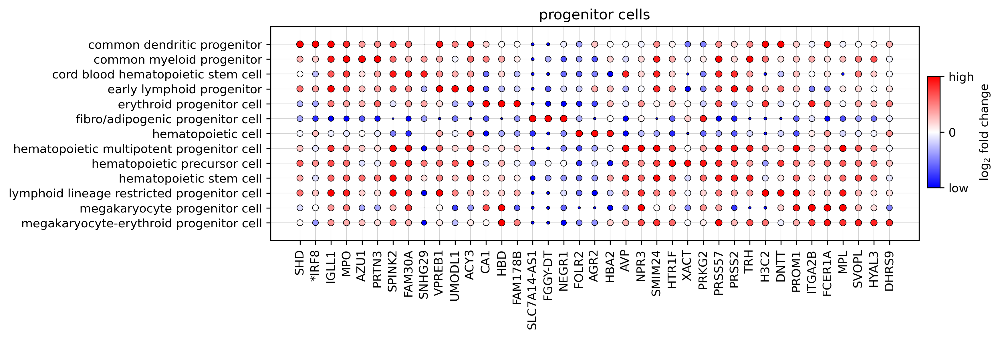

endothelial cells
	17 cell types
	51 unique genes selected (3 per group)


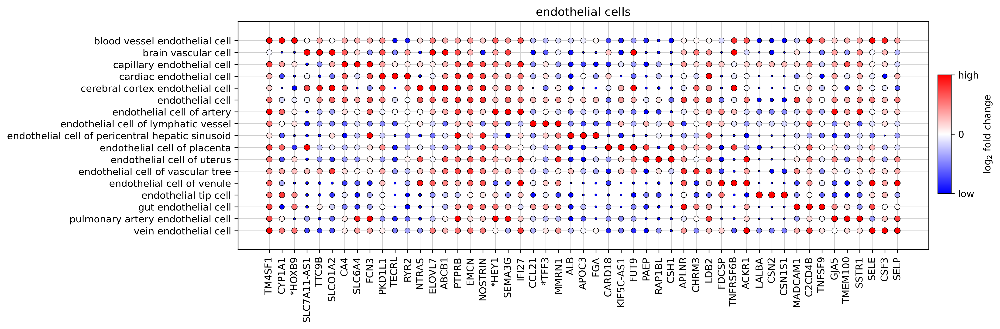

fibroblast/mesenchymal cells
	14 cell types
	42 unique genes selected (3 per group)


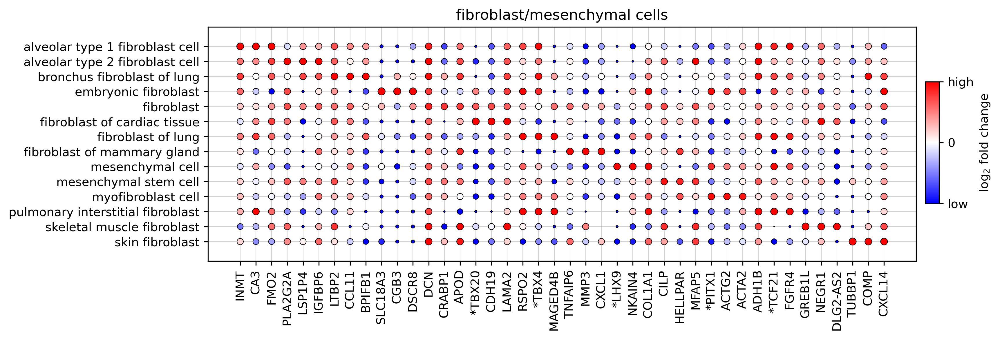

In [34]:
# params
top_n_genes = 3
pct_nz_group = 0.15
pvals_adj = 0.05
logfoldchanges = 1.0

filtered_df = df[
    (df['pct_nz_group'] > pct_nz_group) &
    (df['pvals_adj'] < pvals_adj) &
    (df['logfoldchanges'] > logfoldchanges)
]

# Drop gene classes
filtered_df = filtered_df[
    ~filtered_df['names'].str.contains("ENSG") &
    ~filtered_df['names'].str.startswith(("LINC", "MT", "RP"))
].copy()


for label, cell_list in cell_type_compartments.items():
    print(f"{label} cells")
    n_cell_types = len(cell_list)
    print(f"\t{n_cell_types} cell types")

    # 1. Filter to unique genes by compartment groups
    deg_genes = get_unique_degs(filtered_df, top_n_genes, cell_list)
    n_genes = len(deg_genes)
    print(f"\t{n_genes} unique genes selected ({top_n_genes} per group)")

    cell_list_sorted = sorted(cell_list)
    
    # 2. Now expand to all rows of these genes from all cell_list groups
    pdf = df[(df['names'].isin(deg_genes)) & (df['group'].isin(cell_list_sorted))].copy()
    
    pdf = pdf.sort_values(['group', 'logfoldchanges'], ascending=[True, False])

    # make sure groups and genes are in correct order
    pdf['group'] = pd.Categorical(pdf['group'], categories=cell_list_sorted, ordered=True)
    pdf['names'] = pd.Categorical(pdf['names'], categories=deg_genes, ordered=True)
    
    pdf['label'] = pdf['group'].apply(lambda x: x.replace("_", " "))
    pdf['names'] = pdf['names'].apply(lambda x: f"*{x}" if x in tf_list else x) # annotate TFs
    
    plt.rcParams['figure.dpi'] = 300
    plt.rcParams['figure.figsize'] = (n_genes * 0.25), (n_cell_types * 0.25)

    sns.scatterplot(
        data=pdf,
        x='names',
        y='label',
        hue='logfoldchanges',
        size='logfoldchanges',
        sizes=(0, np.sqrt(n_cell_types * n_genes)*1.5),
        ec='k',
        lw=0.5,
        palette='bwr',
        legend=False,
        zorder=3,
        hue_norm=(-5, 5),
    )

    plt.margins(y=0.1)
    plt.title(f"{label} cells")
    plt.gca().tick_params(axis='x', rotation=90)
    plt.grid(True, zorder=0, c='lightgrey', lw=0.5)
    plt.ylabel("")
    plt.xlabel("")

    fig = plt.gcf()
    cmap = plt.get_cmap('bwr')
    norm = mpl.colors.Normalize(vmin=-5, vmax=5)
    cbar_ax = fig.add_axes([0.91, 0.3, 0.015, 0.4])
    cb = mpl.colorbar.ColorbarBase(
        cbar_ax, cmap=cmap, norm=norm, orientation='vertical'
    )
    cb.set_label('log$_2$ fold change', fontsize=10)
    cb.set_ticks([-5, 0, 5])
    cb.set_ticklabels(['low', '0', 'high'])
    plt.show()
    # break

progenitor cells
	13 cell types
	39 unique genes selected (3 per group)


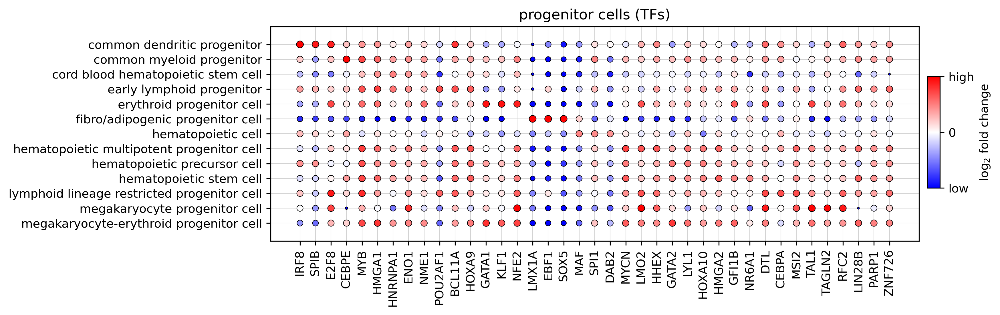

endothelial cells
	17 cell types
	51 unique genes selected (3 per group)


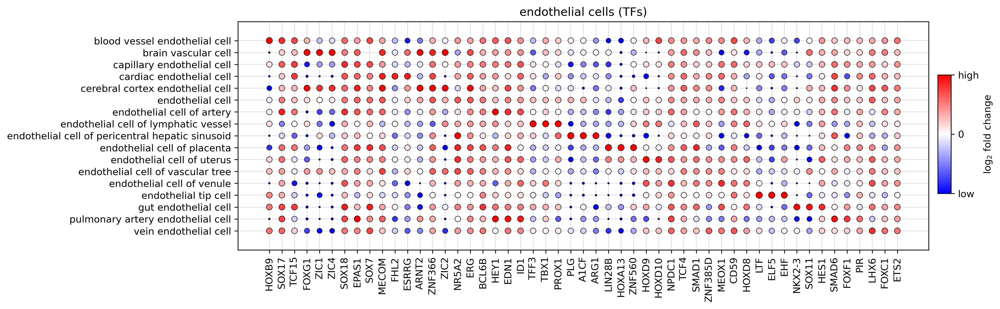

fibroblast/mesenchymal cells
	14 cell types
	42 unique genes selected (3 per group)


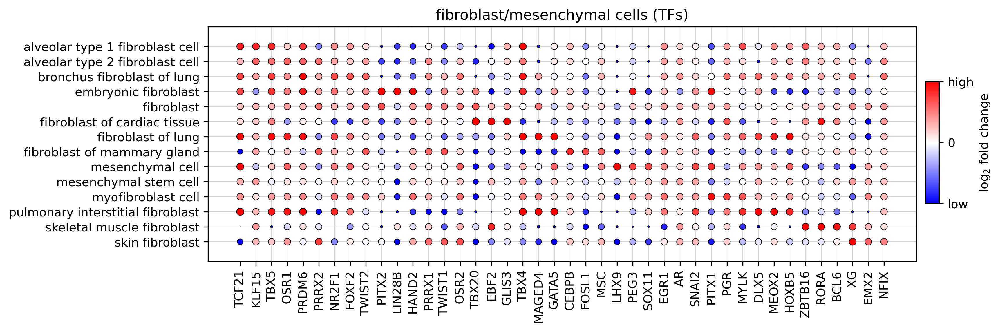

In [35]:
# params
top_n_genes = 3
pct_nz_group = 0.15
pvals_adj = 0.05
logfoldchanges = 1.0

filtered_df = df[
    (df['pct_nz_group'] > pct_nz_group) &
    (df['pvals_adj'] < pvals_adj) &
    (df['logfoldchanges'] > logfoldchanges)
]

# Drop gene classes
filtered_df = filtered_df[
    ~filtered_df['names'].str.contains("ENSG") &
    ~filtered_df['names'].str.startswith(("LINC", "MT", "RP"))
].copy()

# Only TFs!
filtered_df = filtered_df[filtered_df['names'].isin(tf_list)]

for label, cell_list in cell_type_compartments.items():
    print(f"{label} cells")
    n_cell_types = len(cell_list)
    print(f"\t{n_cell_types} cell types")

    # 1. Filter to unique genes by compartment groups
    deg_genes = get_unique_degs(filtered_df, top_n_genes, cell_list)
    n_genes = len(deg_genes)
    print(f"\t{n_genes} unique genes selected ({top_n_genes} per group)")

    cell_list_sorted = sorted(cell_list)
    
    # 2. Now expand to all rows of these genes from all cell_list groups
    pdf = df[(df['names'].isin(deg_genes)) & (df['group'].isin(cell_list_sorted))].copy()
    
    pdf = pdf.sort_values(['group', 'logfoldchanges'], ascending=[True, False])

    # make sure groups and genes are in correct order
    pdf['group'] = pd.Categorical(pdf['group'], categories=cell_list_sorted, ordered=True)
    pdf['names'] = pd.Categorical(pdf['names'], categories=deg_genes, ordered=True)
    
    pdf['label'] = pdf['group'].apply(lambda x: x.replace("_", " "))
    
    plt.rcParams['figure.dpi'] = 300
    plt.rcParams['figure.figsize'] = (n_genes * 0.25), (n_cell_types * 0.25)

    sns.scatterplot(
        data=pdf,
        x='names',
        y='label',
        hue='logfoldchanges',
        size='logfoldchanges',
        sizes=(0, np.sqrt(n_cell_types * n_genes)*1.5),
        ec='k',
        lw=0.5,
        palette='bwr',
        legend=False,
        zorder=3,
        hue_norm=(-5, 5),
    )

    plt.margins(y=0.1)
    plt.title(f"{label} cells (TFs)")
    plt.gca().tick_params(axis='x', rotation=90)
    plt.grid(True, zorder=0, c='lightgrey', lw=0.5)
    plt.ylabel("")
    plt.xlabel("")

    fig = plt.gcf()
    cmap = plt.get_cmap('bwr')
    norm = mpl.colors.Normalize(vmin=-5, vmax=5)
    cbar_ax = fig.add_axes([0.91, 0.3, 0.015, 0.4])
    cb = mpl.colorbar.ColorbarBase(
        cbar_ax, cmap=cmap, norm=norm, orientation='vertical'
    )
    cb.set_label('log$_2$ fold change', fontsize=10)
    cb.set_ticks([-5, 0, 5])
    cb.set_ticklabels(['low', '0', 'high'])
    plt.show()
    # break

progenitor cells
	13 cell types
	32 genes
	n_cell_types * n_genes = 416 (np.sqrt(n_cell_types * n_genes )=np.float64(20.396078054371138))


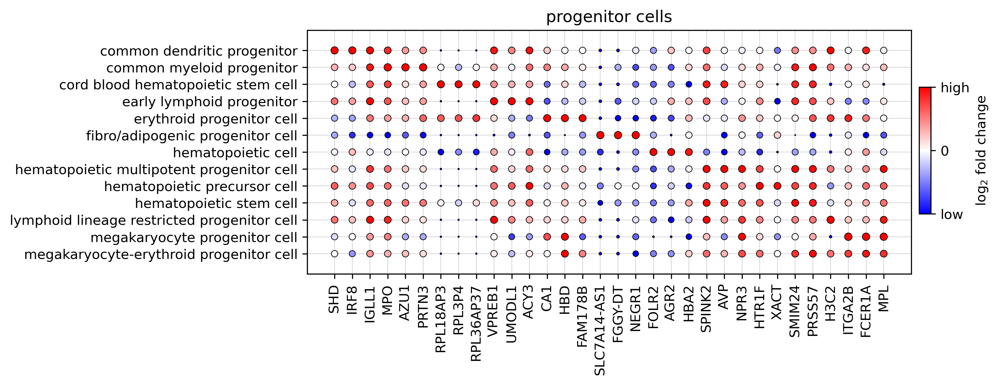

endothelial cells
	17 cell types
	48 genes
	n_cell_types * n_genes = 816 (np.sqrt(n_cell_types * n_genes )=np.float64(28.5657137141714))


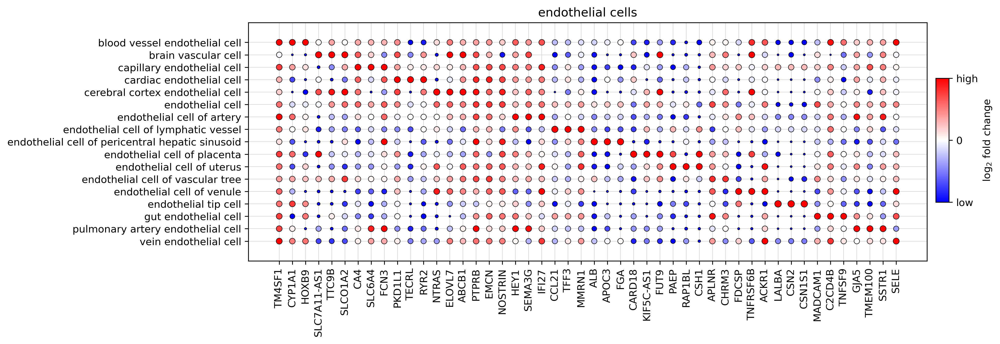

fibroblast/mesenchymal cells
	14 cell types
	41 genes
	n_cell_types * n_genes = 574 (np.sqrt(n_cell_types * n_genes )=np.float64(23.958297101421877))


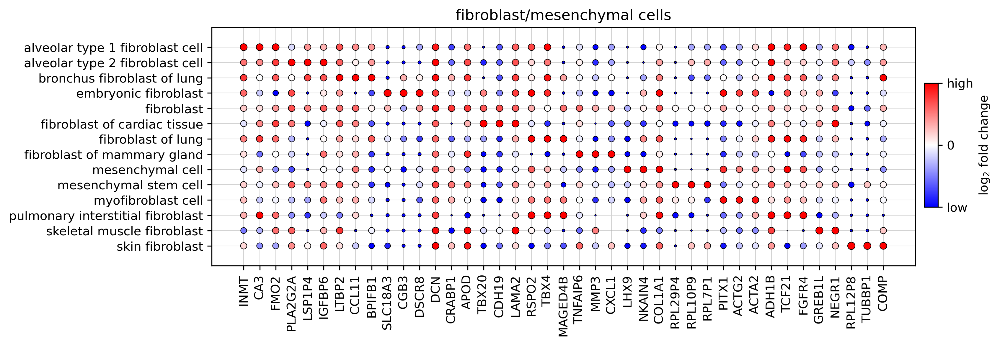

In [32]:
# params
top_n_genes = 3
pct_nz_group = 0.15
pvals_adj = 0.05
logfoldchanges = 1.0

for label, cell_list in cell_type_compartments.items():
    print(f"{label} cells")
    n_cell_types = len(cell_list)
    print(f"\t{n_cell_types} cell types")

    # extract the list of genes for the cell types
    gdf = df.copy()
    gdf = gdf[gdf['group'].isin(cell_list)]
    gdf = gdf[gdf['pct_nz_group'] > pct_nz_group].copy()
    gdf = gdf[gdf['pvals_adj'] < pvals_adj].copy()
    gdf = gdf[gdf['logfoldchanges'] > logfoldchanges].copy()

    # drop certain classes of genes
    gdf = gdf[~gdf['names'].str.contains("ENSG")].copy()
    gdf = gdf[~gdf['names'].str.startswith("LINC")].copy()
    gdf = gdf[~gdf['names'].str.startswith("MT")].copy()
    gdf = gdf[~gdf['names'].str.startswith("RPS")].copy()

    gdf = gdf.groupby('group').head(top_n_genes)

    deg_genes = gdf['names'].unique()
    n_genes = len(deg_genes)
    print(f"\t{n_genes} genes")

    # now filter the full frame for these genes
    pdf = df[df['names'].isin(deg_genes)].copy()
    pdf = pdf[pdf['group'].isin(cell_list)]

    # annotate TFs
    # pdf['names'] = pdf['names'].apply(lambda x: f"*{x}" if x in tf_list else x)
    
    pdf['label'] = pdf['group'].apply(lambda x: x.replace("_", " "))
    pdf = pdf.sort_values(by=['group', 'logfoldchanges'], ascending=[True, False])
    
    pdf['names'] = pd.Categorical(pdf['names'], categories=deg_genes, ordered=True)
    

    plt.rcParams['figure.dpi'] = 300
    plt.rcParams['figure.figsize'] = (n_genes * 0.25), (n_cell_types * 0.25)


    print(f"\t{n_cell_types * n_genes = } ({np.sqrt(n_cell_types * n_genes )=})")
    
    sns.scatterplot(
        data=pdf,
        x='names',
        y='label',
        hue='logfoldchanges',
        size='logfoldchanges',
        sizes=(0, np.sqrt(n_cell_types * n_genes)*1.5),
        ec='k',
        lw=0.5,
        palette='bwr',
        legend=False,
        zorder=3,
        hue_norm=(-5, 5),
    )

    plt.margins(y=0.1)
    plt.title(f"{label} cells")
    plt.gca().tick_params(axis='x', rotation=90)
    plt.grid(True, zorder=0, c='lightgrey', lw=0.5)
    plt.ylabel("")
    plt.xlabel("")
    
    ax = plt.gca()
    y_labels = ax.get_yticklabels()
    y_ticks = ax.get_yticks()

    # Add standalone colorbar to the right
    fig = plt.gcf()
    cmap = plt.get_cmap('bwr')
    norm = mpl.colors.Normalize(vmin=-5, vmax=5)
    
    # [left, bottom, width, height] — adjust as needed
    cbar_ax = fig.add_axes([0.91, 0.3, 0.015, 0.4])
    
    cb = mpl.colorbar.ColorbarBase(
        cbar_ax,
        cmap=cmap,
        norm=norm,
        orientation='vertical'
    )
    
    cb.set_label('log$_2$ fold change', fontsize=10)
    cb.set_ticks([-5, 0, 5])
    cb.set_ticklabels(['low', '0', 'high'])
    
    plt.show()
    # break

lymphoid cells
	45 cell types
	39 genes
	n_cell_types * n_genes = 1755 (np.sqrt(n_cell_types * n_genes )=41.892720131306824)


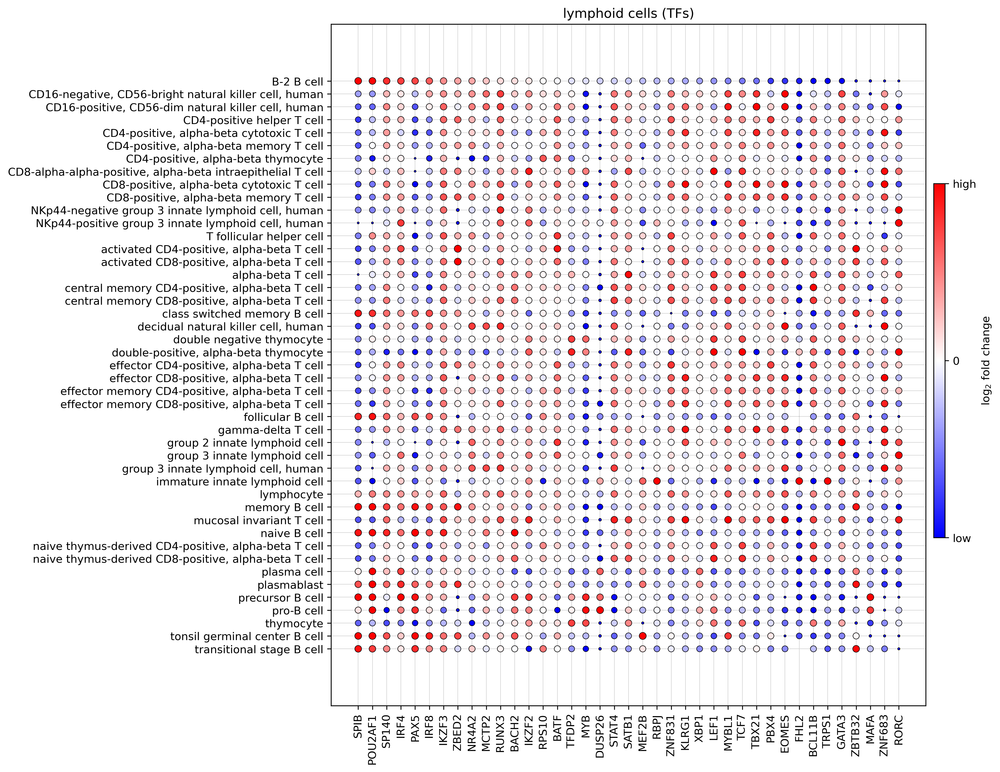

myeloid cells
	13 cell types
	27 genes
	n_cell_types * n_genes = 351 (np.sqrt(n_cell_types * n_genes )=18.734993995195193)


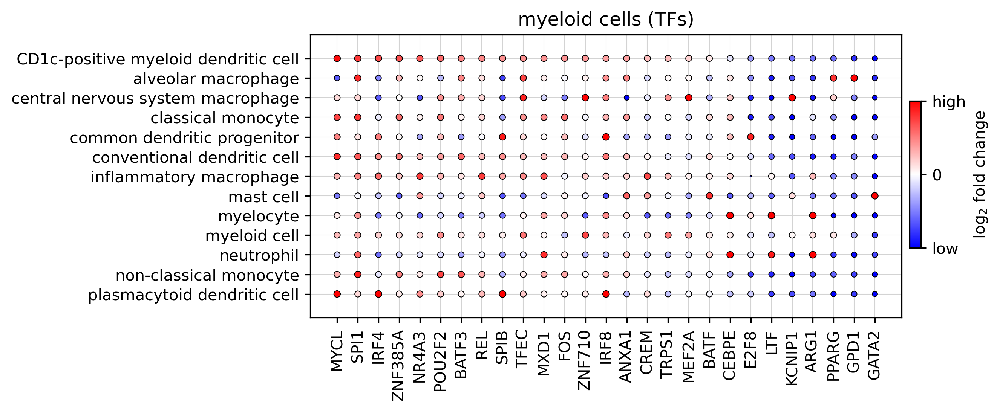

progenitor cells
	13 cell types
	26 genes
	n_cell_types * n_genes = 338 (np.sqrt(n_cell_types * n_genes )=18.384776310850235)


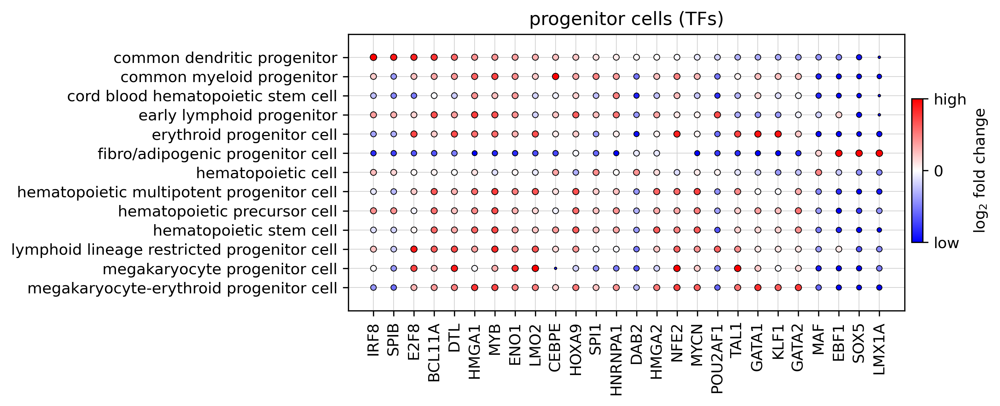

erythroid/megakaryocyte cells
	5 cell types
	8 genes
	n_cell_types * n_genes = 40 (np.sqrt(n_cell_types * n_genes )=6.324555320336759)


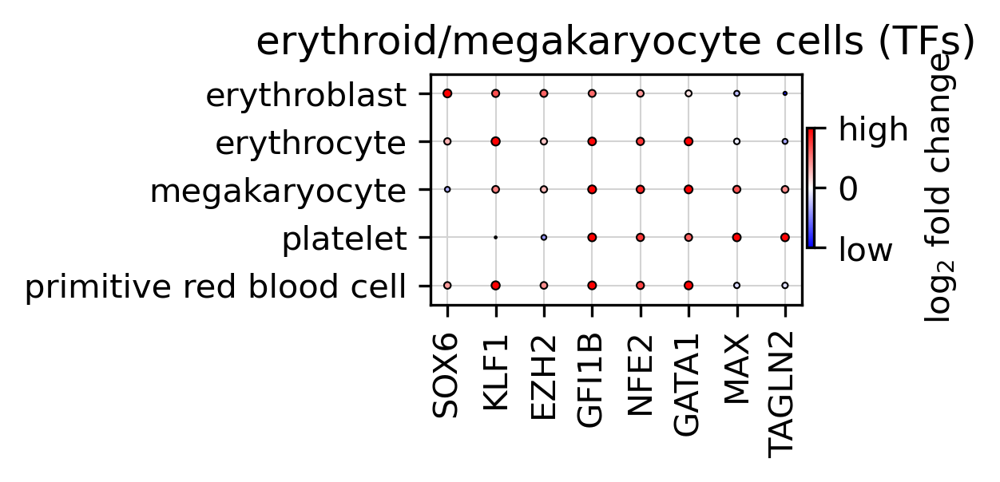

endothelial cells
	17 cell types
	38 genes
	n_cell_types * n_genes = 646 (np.sqrt(n_cell_types * n_genes )=25.41653005427767)


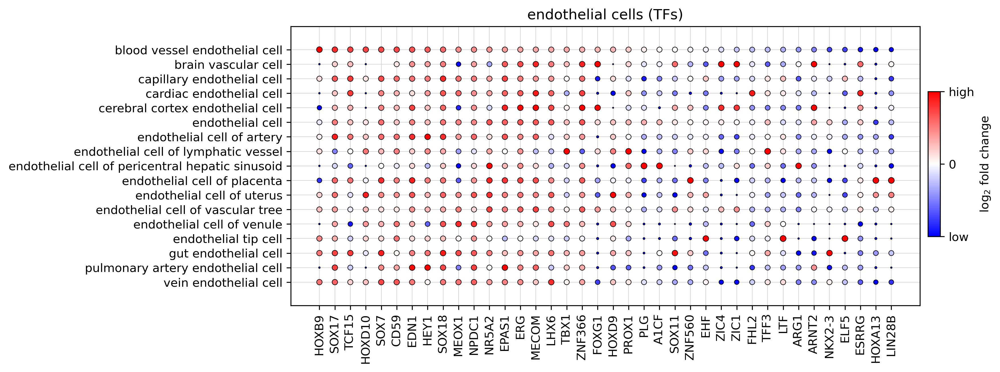

fibroblast/mesenchymal cells
	14 cell types
	33 genes
	n_cell_types * n_genes = 462 (np.sqrt(n_cell_types * n_genes )=21.494185260204677)


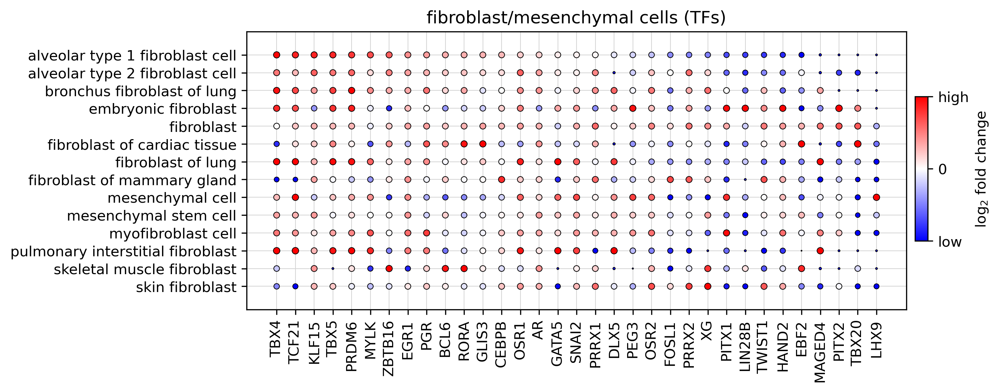

stromal/vascular support cells
	9 cell types
	23 genes
	n_cell_types * n_genes = 207 (np.sqrt(n_cell_types * n_genes )=14.38749456993816)


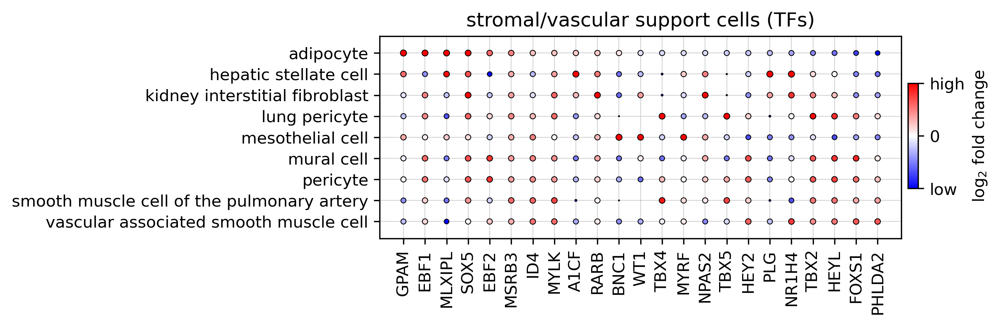

In [7]:
# params
top_n_genes = 3
pct_nz_group = 0.15
pvals_adj = 0.05
logfoldchanges = 1.0

for label, cell_list in cell_type_compartments.items():
    print(f"{label} cells")
    n_cell_types = len(cell_list)
    print(f"\t{n_cell_types} cell types")

    # extract the list of genes for the cell types
    gdf = df.copy()
    gdf = gdf[gdf['group'].isin(cell_list)]
    gdf = gdf[gdf['pct_nz_group'] > pct_nz_group].copy()
    gdf = gdf[gdf['pvals_adj'] < pvals_adj].copy()
    gdf = gdf[gdf['logfoldchanges'] > logfoldchanges].copy()

    # only TFs!
    gdf = gdf[gdf['names'].isin(tf_list)].copy()
    gdf = gdf.groupby('group').head(top_n_genes)

    deg_genes = gdf['names'].unique()
    n_genes = len(deg_genes)
    print(f"\t{n_genes} genes")

    # now filter the full frame for these genes
    pdf = df[df['names'].isin(deg_genes)].copy()
    pdf = pdf[pdf['group'].isin(cell_list)]

    # annotate TFs
    # pdf['names'] = pdf['names'].apply(lambda x: f"*{x}" if x in tf_list else x)
    
    pdf['label'] = pdf['group'].apply(lambda x: x.replace("_", " "))
    pdf = pdf.sort_values(by=['group', 'logfoldchanges'], ascending=[True, False])
    
    plt.rcParams['figure.dpi'] = 300
    plt.rcParams['figure.figsize'] = (n_genes * 0.25), (n_cell_types * 0.25)

    print(f"\t{n_cell_types * n_genes = } ({np.sqrt(n_cell_types * n_genes )=})")
    
    sns.scatterplot(
        data=pdf,
        x='names',
        y='label',
        hue='logfoldchanges',
        size='logfoldchanges',
        sizes=(0, np.sqrt(n_cell_types * n_genes )),
        ec='k',
        lw=0.5,
        palette='bwr',
        legend=False,
        zorder=3,
        hue_norm=(-5, 5),
    )

    plt.margins(y=0.1)
    plt.title(f"{label} cells (TFs)")
    plt.gca().tick_params(axis='x', rotation=90)
    plt.grid(True, zorder=0, c='lightgrey', lw=0.5)
    plt.ylabel("")
    plt.xlabel("")
    
    ax = plt.gca()
    y_labels = ax.get_yticklabels()
    y_ticks = ax.get_yticks()

    # Add standalone colorbar to the right
    fig = plt.gcf()
    cmap = plt.get_cmap('bwr')
    norm = mpl.colors.Normalize(vmin=-5, vmax=5)
    
    # [left, bottom, width, height] — adjust as needed
    cbar_ax = fig.add_axes([0.91, 0.3, 0.015, 0.4])
    
    cb = mpl.colorbar.ColorbarBase(
        cbar_ax,
        cmap=cmap,
        norm=norm,
        orientation='vertical'
    )
    
    cb.set_label('log$_2$ fold change', fontsize=10)
    cb.set_ticks([-5, 0, 5])
    cb.set_ticklabels(['low', '0', 'high'])
    
    plt.show()